# CNN + BiLTSM

## Cargar librerías

In [1]:
import os, random, numpy as np
from pathlib import Path
from typing import Dict, Any

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms, models
from torchvision.datasets import ImageFolder

import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor, Callback
from pytorch_lightning.loggers import CSVLogger
from torchmetrics.classification import (
    MulticlassAccuracy, MulticlassPrecision,
    MulticlassRecall, MulticlassF1Score
)

In [2]:
print("torch version:", torch.__version__)
print("cuda_is_available:", torch.cuda.is_available())
print("num_devices:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("device 0:", torch.cuda.get_device_name(0))


torch version: 2.5.1
cuda_is_available: True
num_devices: 1
device 0: NVIDIA GeForce RTX 3050 Laptop GPU


## CONFIG

In [ ]:
DATA_ROOT    = Path(r"C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\GTZAN5Seg_LogMel")   # <-- AJUSTA
SPLITS       = {"train": "train", "val": "val", "test": "test"}

IMG_SIZE     = (224, 224)
BATCH_SIZE   = 16
NUM_WORKERS  = 0 if os.name == "nt" else 4
MAX_EPOCHS   = 80
LR           = 2e-4
WD           = 1e-4
DROPOUT      = 0.3
LSTM_HIDDEN  = 256
LSTM_LAYERS  = 2
SEED         = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.set_float32_matmul_precision("high")

## DATAMODULE

In [4]:
class SpectrogramDataModule(pl.LightningDataModule):
    def __init__(self, data_root: Path, splits: dict, batch_size: int, num_workers: int):
        super().__init__()
        self.data_root   = Path(data_root)
        self.splits      = splits
        self.batch_size  = batch_size
        self.num_workers = num_workers
        self.tx_train = transforms.Compose([
            transforms.Grayscale(num_output_channels=1),
            transforms.Resize(IMG_SIZE, antialias=True),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5], std=[0.5]),
        ])
        self.tx_eval = transforms.Compose([
            transforms.Grayscale(num_output_channels=1),
            transforms.Resize(IMG_SIZE, antialias=True),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5], std=[0.5]),
        ])
    def setup(self, stage=None):
        root = self.data_root
        self.ds_train = ImageFolder(root / self.splits["train"], transform=self.tx_train)
        self.ds_val   = ImageFolder(root / self.splits["val"],   transform=self.tx_eval)
        self.ds_test  = ImageFolder(root / self.splits["test"],  transform=self.tx_eval)
        self.num_classes = len(self.ds_train.classes)
    def train_dataloader(self):
        return DataLoader(self.ds_train, batch_size=self.batch_size, shuffle=True,
                          num_workers=self.num_workers, pin_memory=True)
    def val_dataloader(self):
        return DataLoader(self.ds_val, batch_size=self.batch_size, shuffle=False,
                          num_workers=self.num_workers, pin_memory=True)
    def test_dataloader(self):
        return DataLoader(self.ds_test, batch_size=self.batch_size, shuffle=False,
                          num_workers=self.num_workers, pin_memory=True)

## MODELO

In [5]:
import math

class PatchEmbedding(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_chans=1, embed_dim=256):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.grid_size = img_size // patch_size  # 14 si 224/16
        self.num_patches = self.grid_size * self.grid_size

        # Equivalente a: dividir en parches, aplanar y pasar por Linear
        self.proj = nn.Conv2d(
            in_chans,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):
        # x: [B, C, H, W]  C=1 canal, Mel-log 2D
        B, C, H, W = x.shape
        # Garantizamos 224x224 (si por alguna razón viene otra cosa)
        if H != self.img_size or W != self.img_size:
            x = F.interpolate(
                x,
                size=(self.img_size, self.img_size),
                mode="bilinear",
                align_corners=False,
            )
        x = self.proj(x)          # [B, D, H/ps, W/ps] = [B, D, 14, 14]
        x = x.flatten(2)          # [B, D, N]
        x = x.transpose(1, 2)     # [B, N, D]  N=196
        return x


class ViTEncoderBlock(nn.Module):
    def __init__(
        self,
        embed_dim: int,
        num_heads: int,
        mlp_ratio: float = 4.0,
        dropout: float = 0.1,
        attn_dropout: float = 0.1,
    ):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(
            embed_dim,
            num_heads,
            dropout=attn_dropout,
            batch_first=True,
        )
        self.norm2 = nn.LayerNorm(embed_dim)
        hidden_dim = int(embed_dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        # x: [B, 1+N, D]
        # Multi-Head Self-Attention + residual
        x_norm = self.norm1(x)
        attn_out, _ = self.attn(x_norm, x_norm, x_norm)  # MHSA
        x = x + attn_out

        # MLP + residual
        x_norm = self.norm2(x)
        x = x + self.mlp(x_norm)
        return x


class ViTClassifier(pl.LightningModule):
    def __init__(
        self,
        num_classes: int,
        img_size: int = 224,
        patch_size: int = 16,
        in_chans: int = 1,
        embed_dim: int = 256,
        depth: int = 8,
        num_heads: int = 8,
        mlp_ratio: float = 4.0,
        dropout: float = 0.1,
        attn_dropout: float = 0.1,
        lr: float = LR,
        wd: float = WD,
    ):
        super().__init__()
        self.save_hyperparameters()

        # Patch embedding (parches 16x16 → N parches, proyección lineal a D)
        self.patch_embed = PatchEmbedding(
            img_size=img_size,
            patch_size=patch_size,
            in_chans=in_chans,
            embed_dim=embed_dim,
        )
        num_patches = self.patch_embed.num_patches  # 196 si 224x224

        # Token [CLS]
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        # Embeddings posicionales (tiempo-frecuencia codificada en la secuencia)
        self.pos_embed = nn.Parameter(torch.zeros(1, 1 + num_patches, embed_dim))
        self.pos_drop = nn.Dropout(dropout)

        # Encoder ViT: L bloques con MHSA + MLP (GELU), residual, LayerNorm, dropout
        self.blocks = nn.ModuleList([
            ViTEncoderBlock(
                embed_dim=embed_dim,
                num_heads=num_heads,
                mlp_ratio=mlp_ratio,
                dropout=dropout,
                attn_dropout=attn_dropout,
            )
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)

        # Head lineal + softmax implícito en CrossEntropyLoss
        self.head = nn.Linear(embed_dim, num_classes)

        # Cross-entropy con label smoothing
        self.crit = nn.CrossEntropyLoss(label_smoothing=0.1)

        # Inicialización simple
        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embed, std=0.02)
        nn.init.xavier_uniform_(self.head.weight)
        if self.head.bias is not None:
            nn.init.zeros_(self.head.bias)

        # Métricas (macro)
        self.train_acc  = MulticlassAccuracy(num_classes=num_classes, average='macro')
        self.val_acc    = MulticlassAccuracy(num_classes=num_classes, average='macro')
        self.test_acc   = MulticlassAccuracy(num_classes=num_classes, average='macro')

        self.train_prec = MulticlassPrecision(num_classes=num_classes, average='macro')
        self.val_prec   = MulticlassPrecision(num_classes=num_classes, average='macro')
        self.test_prec  = MulticlassPrecision(num_classes=num_classes, average='macro')

        self.train_rec  = MulticlassRecall(num_classes=num_classes, average='macro')
        self.val_rec    = MulticlassRecall(num_classes=num_classes, average='macro')
        self.test_rec   = MulticlassRecall(num_classes=num_classes, average='macro')

        self.train_f1   = MulticlassF1Score(num_classes=num_classes, average='macro')
        self.val_f1     = MulticlassF1Score(num_classes=num_classes, average='macro')
        self.test_f1    = MulticlassF1Score(num_classes=num_classes, average='macro')

    # --------- forward: encoder ViT completo ---------

    def forward(self, x):
        # x: [B, 1, H, W] Mel-log 2D ya preprocesado (incluyendo z-score si lo aplicas en el pipeline)
        x = self.patch_embed(x)           # [B, N, D]
        B, N, D = x.shape

        cls_tokens = self.cls_token.expand(B, -1, -1)  # [B, 1, D]
        x = torch.cat((cls_tokens, x), dim=1)          # [B, 1+N, D]
        x = x + self.pos_embed                         # suma de embeddings posicionales
        x = self.pos_drop(x)

        for blk in self.blocks:
            x = blk(x)

        x = self.norm(x)
        cls_repr = x[:, 0]                 # representación del [CLS]
        logits = self.head(cls_repr)       # [B, num_classes]
        return logits

    # --------- pasos compartidos (train/val/test) ---------

    def _shared_step(self, batch, stage: str):
        x, y = batch
        logits = self(x)
        loss = self.crit(logits, y)
        preds = torch.argmax(logits, dim=1)

        if stage == "train":
            self.train_acc(preds, y)
            self.train_prec(preds, y)
            self.train_rec(preds, y)
            self.train_f1(preds, y)
        elif stage == "val":
            self.val_acc(preds, y)
            self.val_prec(preds, y)
            self.val_rec(preds, y)
            self.val_f1(preds, y)
        elif stage == "test":
            self.test_acc(preds, y)
            self.test_prec(preds, y)
            self.test_rec(preds, y)
            self.test_f1(preds, y)

        self.log(
            f"{stage}/loss",
            loss,
            on_step=False,
            on_epoch=True,
            prog_bar=(stage != "test"),
            batch_size=x.size(0),
        )
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def test_step(self, batch, batch_idx):
        self._shared_step(batch, "test")

    # --------- agrego métricas por época ---------

    def on_train_epoch_end(self):
        acc = self.train_acc.compute();   self.train_acc.reset()
        pr  = self.train_prec.compute();  self.train_prec.reset()
        rc  = self.train_rec.compute();   self.train_rec.reset()
        f1  = self.train_f1.compute();    self.train_f1.reset()
        self.log_dict(
            {'train/acc': acc, 'train/prec': pr, 'train/rec': rc, 'train/f1': f1},
            prog_bar=True,
        )

    def on_validation_epoch_end(self):
        acc = self.val_acc.compute();   self.val_acc.reset()
        pr  = self.val_prec.compute();  self.val_prec.reset()
        rc  = self.val_rec.compute();   self.val_rec.reset()
        f1  = self.val_f1.compute();    self.val_f1.reset()
        self.log_dict(
            {'val/acc': acc, 'val/prec': pr, 'val/rec': rc, 'val/f1': f1},
            prog_bar=True,
        )

    def on_test_epoch_end(self):
        acc = self.test_acc.compute();   self.test_acc.reset()
        pr  = self.test_prec.compute();  self.test_prec.reset()
        rc  = self.test_rec.compute();   self.test_rec.reset()
        f1  = self.test_f1.compute();    self.test_f1.reset()
        self.log_dict(
            {'test/acc': acc, 'test/prec': pr, 'test/rec': rc, 'test/f1': f1},
            prog_bar=True,
        )

    # --------- optimizador + scheduler (AdamW + Cosine + warmup) ---------

    def configure_optimizers(self):
        opt = torch.optim.AdamW(
            self.parameters(),
            lr=self.hparams.lr,
            weight_decay=self.hparams.wd,
        )

        def sch_lambda(epoch):
            warmup = 5
            if epoch < warmup:
                return (epoch + 1) / warmup
            t = (epoch - warmup) / max(1, (MAX_EPOCHS - warmup))
            return 0.5 * (1.0 + math.cos(math.pi * t))

        sch = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda=sch_lambda)
        return {"optimizer": opt, "lr_scheduler": sch}


## Callback

In [6]:
class EpochMetricsPrinter(Callback):
    """Imprime métricas de train/val al cierre de cada época."""
    KEYS = [
        'train/loss','train/acc','train/prec','train/rec','train/f1',
        'val/loss','val/acc','val/prec','val/rec','val/f1'
    ]
    def _fmt(self, x: Any):
        try:
            return f"{float(x):.4f}"
        except Exception:
            return str(x)
    def on_validation_epoch_end(self, trainer: pl.Trainer, pl_module: pl.LightningModule):
        m: Dict[str, Any] = trainer.callback_metrics
        e = trainer.current_epoch
        vals = {k:self._fmt(m.get(k, float('nan'))) for k in self.KEYS}
        print(
            f"[Epoch {e:03d}] "
            f"TRAIN: loss={vals['train/loss']}  acc={vals['train/acc']}  "
            f"prec={vals['train/prec']}  rec={vals['train/rec']}  f1={vals['train/f1']}  |  "
            f"VAL: loss={vals['val/loss']}  acc={vals['val/acc']}  "
            f"prec={vals['val/prec']}  rec={vals['val/rec']}  f1={vals['val/f1']}"
        )

## Entrenamiento

In [7]:
def run_training():
    dm = SpectrogramDataModule(DATA_ROOT, SPLITS, BATCH_SIZE, NUM_WORKERS)
    dm.setup()
    print("Clases:", dm.ds_train.classes)
    print(f"train={len(dm.ds_train)} | val={len(dm.ds_val)} | test={len(dm.ds_test)}")

    model = ViTClassifier(
        num_classes=dm.num_classes,
        img_size=224,
        patch_size=16,
        in_chans=1,
        embed_dim=256,   # puedes subir a 384/512 si tu GPU aguanta
        depth=8,         # número de bloques ViT (L)
        num_heads=8,     # heads de atención
        mlp_ratio=4.0,
        dropout=DROPOUT,
        attn_dropout=0.1,
        lr=LR,
        wd=WD,
    )

    ckpt = ModelCheckpoint(
        monitor='val/acc',
        mode='max',
        save_top_k=1,
        save_last=True,
        filename='vit-{epoch:02d}-{val_acc:.3f}',
    )
    early  = EarlyStopping(monitor='val/acc', mode='max', patience=10)
    lrmon  = LearningRateMonitor(logging_interval='epoch')
    logger = CSVLogger("logs", name="vit")
    printer = EpochMetricsPrinter()

    trainer = pl.Trainer(
        max_epochs=MAX_EPOCHS,
        accelerator='auto',
        devices='auto',
        precision='16-mixed',   # si estás en CPU solo, cambia a '32-true'
        callbacks=[ckpt, early, lrmon, printer],
        logger=[logger],
        log_every_n_steps=25,
    )

    trainer.fit(model, datamodule=dm)
    print("Best ckpt:", ckpt.best_model_path or "<none>", "| best:", ckpt.best_model_score)
    trainer.test(model=None, datamodule=dm, ckpt_path=('best' if ckpt.best_model_path else None))
    print("CSV logs:", logger.log_dir)

if __name__ == "__main__":
    run_training()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores


Clases: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
train=29323 | val=1196 | test=600


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\RICHI\anaconda3\envs\TesisRichiFix2\Lib\site-packages\pytorch_lightning\utilities\model_summary\model_summary.py:231: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.

   | Name         | Type                | Params | Mode 
--------------------------------------------------------------
0  | patch_embed  | PatchEmbedding      | 65.8 K | train
1  | pos_drop     | Dropout             | 0      | train
2  | blocks       | ModuleList          | 6.3 M  | train
3  | norm         | LayerNorm           | 512    | train
4  | head         | Linear              | 2.6 K  | train
5  | crit         | CrossEntropyLoss    | 0      | train
6  | train_acc    | MulticlassAccuracy  | 0      | train
7  | val_acc      | MulticlassAccuracy  | 0      | train
8  | test_acc     | MulticlassAccuracy  | 0      | train
9  | train_prec   | MulticlassPrecision | 0      | train
10 | val_

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

c:\Users\RICHI\anaconda3\envs\TesisRichiFix2\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:433: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


...

c:\Users\RICHI\anaconda3\envs\TesisRichiFix2\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:433: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Epoch 55:  73%|███████▎  | 1347/1833 [02:03<00:44, 10.89it/s, v_num=8, val/loss=1.880, val/acc=0.589, val/prec=0.581, val/rec=0.589, val/f1=0.578, train/loss=0.534, train/acc=0.986, train/prec=0.986, train/rec=0.986, train/f1=0.986]


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

c:\Users\RICHI\anaconda3\envs\TesisRichiFix2\Lib\site-packages\IPython\core\interactiveshell.py:3707: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [9]:
# === Utils: versión reciente, curvas loss (desde CSVLogger), preds.csv, reporte y CM ===
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Ajusta si cambiaste el nombre del experimento en CSVLogger
LOG_ROOT = Path(r"C:\Users\RICHI\Documents\Tesis\TesisRichi\codigo\logs\vit")

def latest_version_dir(log_root: Path) -> Path:
    if not log_root.exists():
        raise FileNotFoundError(f"No existe {log_root}")
    versions = sorted([p for p in log_root.glob("version_*") if p.is_dir()],
                      key=lambda p: int(re.sub(r".*_(\d+)$", r"\1", p.name)))
    return versions[-1] if versions else log_root

def pick_ckpt(version_dir: Path) -> Path:
    ckpt_dir = version_dir / "checkpoints"
    if not ckpt_dir.exists():
        raise FileNotFoundError(f"No existe {ckpt_dir}")
    # Preferir last.ckpt; si no, el más reciente por mtime.
    last = ckpt_dir / "last.ckpt"
    if last.exists(): 
        return last
    ckpts = sorted(ckpt_dir.glob("*.ckpt"), key=lambda p: p.stat().st_mtime)
    if not ckpts:
        raise FileNotFoundError(f"Sin .ckpt en {ckpt_dir}")
    return ckpts[-1]

def plot_losses_from_metrics(version_dir: Path, save_as: Path | None = None, smooth: int | None = 3):
    metrics_path = version_dir / "metrics.csv"
    if not metrics_path.exists():
        raise FileNotFoundError(f"No existe {metrics_path}")
    df = pd.read_csv(metrics_path)
    # normaliza nombres: train/loss -> train_loss; val.loss -> val_loss; quita espacios
    df.columns = [re.sub(r"[\/\.\:\s]+", "_", str(c).strip()) for c in df.columns]
    # colapsa duplicadas (evita TypeError en to_numeric)
    if df.columns.duplicated().any():
        df = df.T.groupby(level=0).last().T
    # eje x: epoch > step > índice
    epoch_col = "epoch" if "epoch" in df.columns else ("step" if "step" in df.columns else None)
    if epoch_col is None:
        df["epoch"] = np.arange(len(df)); epoch_col = "epoch"
    # convierte a numérico (excepto x)
    num_cols = [c for c in df.columns if c != epoch_col]
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
    # último registro por época/paso
    sdf = df.groupby(epoch_col, as_index=False).agg({c: "last" for c in num_cols})
    # detectar columnas de pérdida
    loss_cols = [c for c in sdf.columns if c != epoch_col and "loss" in c.lower() and not c.lower().endswith("_step") and sdf[c].notna().any()]
    train_like = [c for c in loss_cols if any(k in c.lower() for k in ["train","tr","training"])]
    val_like   = [c for c in loss_cols if any(k in c.lower() for k in ["val","valid","validation"])]
    to_plot = (sorted(train_like) + sorted(val_like)) or sorted(loss_cols)
    if not to_plot:
        raise RuntimeError(f"No hay columnas de pérdida para graficar. Columnas: {list(sdf.columns)}")
    def smooth_series(s, w):
        if not w or w <= 1 or len(s) < w: return s
        return pd.Series(s).rolling(window=w, min_periods=1).mean()
    plt.figure()
    for c in to_plot:
        y = smooth_series(sdf[c], smooth)
        plt.plot(sdf[epoch_col], y, label=c)
    plt.xlabel(epoch_col); plt.ylabel("loss"); plt.title("Curvas de pérdida (train/val)")
    plt.legend()
    if save_as:
        save_as.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_as, bbox_inches="tight")
    plt.show()

@torch.no_grad()
def export_preds_and_metrics(ckpt_path: Path, dm, split: str, out_dir: Path):
    model = ViTClassifier.load_from_checkpoint(str(ckpt_path))
    model.eval().cuda() if torch.cuda.is_available() else model.eval()

    # obtener dataloader según split
    if split == "val":
        loader = dm.val_dataloader()
    elif split == "test":
        loader = dm.test_dataloader()
    else:
        raise ValueError("split debe ser 'val' o 'test'")

    y_true, y_pred = [], []
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    for batch in loader:
        x, y = batch
        x = x.to(device); y = y.to(device)
        logits = model(x)
        preds = logits.argmax(1)
        y_true.append(y.detach().cpu().numpy())
        y_pred.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(y_true); y_pred = np.concatenate(y_pred)
    out_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"y_true": y_true, "y_pred": y_pred}).to_csv(out_dir / "preds.csv", index=False)

    print(classification_report(y_true, y_pred, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)

    # Azul claro→oscuro a mayor conteo
    try:
        disp.plot(cmap="Blues", values_format="d", colorbar=True)
    except TypeError:  # versiones antiguas de sklearn sin colorbar=
        disp.plot(cmap="Blues", values_format="d")
        plt.colorbar(disp.im_, ax=plt.gca())


    ConfusionMatrixDisplay(cm).plot(values_format="d")
    plt.title(f"Matriz de confusión ({split})")
    plt.tight_layout()
    plt.savefig("confusion_matrix_blues.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.show()


Versión analizada: C:\Users\RICHI\Documents\Tesis\TesisRichi\codigo\logs\vit\version_7


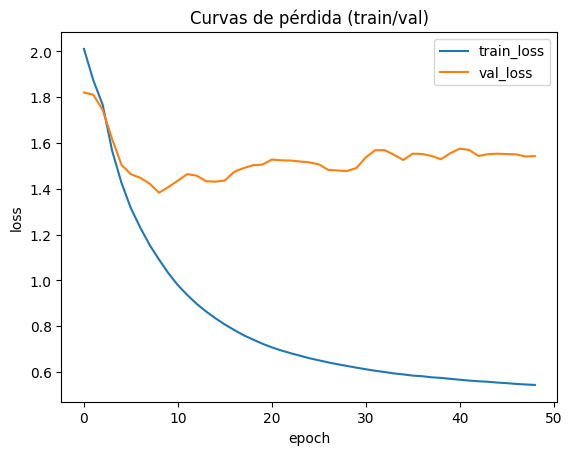

Checkpoint usado: last.ckpt
              precision    recall  f1-score   support

           0     0.8906    0.9500    0.9194       120
           1     0.7287    0.7833    0.7550       120
           2     0.8987    0.5917    0.7136       120
           3     0.7016    0.7250    0.7131       120
           4     0.3429    0.4000    0.3692       120
           5     0.8167    0.4083    0.5444       120
           6     0.7984    0.8583    0.8273       120
           7     0.7097    0.9167    0.8000       120
           8     0.6818    0.5042    0.5797       119
           9     0.6527    0.9083    0.7596       120

    accuracy                         0.7048      1199
   macro avg     0.7222    0.7046    0.6981      1199
weighted avg     0.7222    0.7048    0.6982      1199



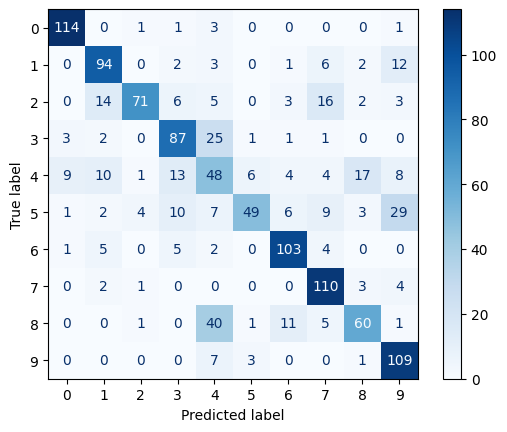

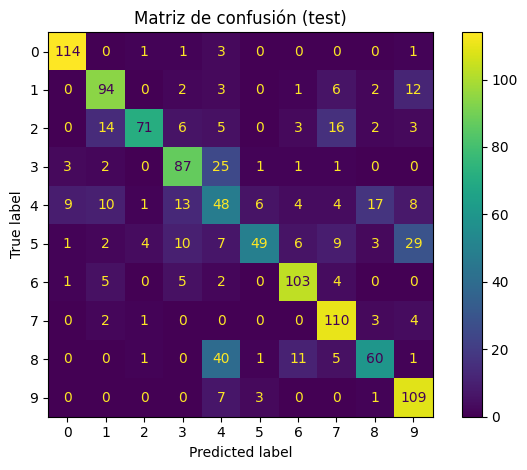

In [10]:
# === Ejecutar ANÁLISIS tras el entrenamiento ===
# Recrea el DataModule con los mismos hiperparámetros usados en run_training()
dm = SpectrogramDataModule(DATA_ROOT, SPLITS, BATCH_SIZE, NUM_WORKERS)
dm.setup()

version_dir = latest_version_dir(LOG_ROOT)
print("Versión analizada:", version_dir)

# Curvas de pérdida desde metrics.csv del CSVLogger
plot_losses_from_metrics(version_dir, save_as=version_dir / "loss_curves.png", smooth=3)

# Escoge checkpoint (last.ckpt o el más reciente) y exporta métricas + preds.csv
ckpt_path = pick_ckpt(version_dir)
print("Checkpoint usado:", ckpt_path.name)

# Usa 'test' si quieres métricas finales del conjunto de prueba; 'val' para validación
export_preds_and_metrics(ckpt_path, dm, split="test", out_dir=version_dir)
